# Estimación de la inflación en Colombia mediante el modelo de Hull-White

## Modelo para la estimación.

El modelo de Hull-White es una herramienta estocástica y financiera para predecir tasas de interés a corto plazo utilizando aleatoriedad con una tendencia a volver a un nivel promedio a lo largo del tiempo. Es decir, las tasas de interés pueden fluctuar aleatoriamente pero tienden a retroceder hacia un promedio de largo plazo.

### Ecuación

$dI_{t} = (\theta (t) - aI_{t})dt + \sigma dW_{t}$

donde:
* a: Velocidad de reversión a la media 
* $\sigma$: Volatilidad instantanea del proceso
* $\theta$: Nivel medio a largo plazo
* $dW_{t}$: Incremento del proceso de Wiener

### Estimación de los parámetros

Al integrar la EDE utilizando el factor integrante mediante el Lema de Itô, se obtiene un modelo autorregresivo de orden 1:

$I_{t+\Delta t} = \alpha + \beta I_{t} + \epsilon_{t+\delta t}$

* $\beta = e^{-a\Delta t}$
* $\alpha = \theta(1 - e^{-a\Delta t})$
* $Var(\epsilon) = \frac{\sigma^2}{2a}(1 - e^{-2a\Delta t})$

# Simulación

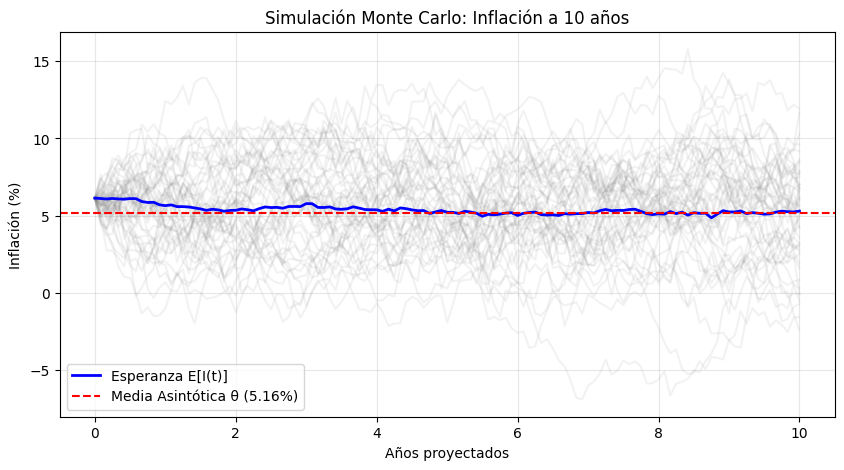

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import statsmodels.api as sm

df = pd.read_csv('inflation_history_colombia.csv', sep=';', decimal=',', parse_dates=['DateTime'])
df = df.set_index('DateTime')
df_2016 = df[df.index >= '2016-01-01'].copy()
ts = df_2016['Inflación total anual'].dropna() / 100.0

ts_semestral = ts[ts.index.month.isin([6, 12])]

Y = ts_semestral.values[1:]
X = ts_semestral.values[:-1]
X = sm.add_constant(X)

model = sm.OLS(Y, X).fit()
alpha, beta = model.params
var_eps = model.mse_resid
dt = 0.5

a = -np.log(beta) / dt
sigma = np.sqrt((2 * a * var_eps) / (1 - beta**2))
theta = alpha / (1 - beta)

# 2. Configuración del espacio de simulación
T = 10 
dt_sim = 1/12  
N = int(T / dt_sim) 
M = 500

# 3. Inicialización matricial y condición de frontera
paths = np.zeros((M, N + 1))
I0 = Y[-1]  
paths[:, 0] = I0

# 4. Integración estocástica (Euler-Maruyama)
np.random.seed(42)
for t in range(1, N + 1):
    Z = np.random.standard_normal(M)
    drift = a * (theta - paths[:, t - 1]) * dt_sim
    diffusion = sigma * np.sqrt(dt_sim) * Z
    paths[:, t] = paths[:, t - 1] + drift + diffusion

# 5. Renderizado gráfico de las trayectorias
import matplotlib.pyplot as plt

time_axis = np.linspace(0, T, N + 1)
plt.figure(figsize=(10, 5))
plt.plot(time_axis, paths[:50, :].T * 100, color='gray', alpha=0.1) 
plt.plot(time_axis, np.median(paths, axis=0) * 100, color='blue', linewidth=2, label='Esperanza E[I(t)]')
plt.axhline(theta * 100, color='red', linestyle='--', label=f'Media Asintótica θ ({theta*100:.2f}%)')
plt.title('Simulación Monte Carlo: Inflación a 10 años')
plt.xlabel('Años proyectados')
plt.ylabel('Inflación (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [2]:
np.mean(paths, axis=0)

array([0.0614    , 0.06120209, 0.06144618, 0.06113265, 0.06062342,
       0.05987503, 0.05917558, 0.05865869, 0.05856066, 0.05845885,
       0.0581044 , 0.05752773, 0.05721462, 0.05708121, 0.05741892,
       0.05746737, 0.05718998, 0.05723452, 0.05729769, 0.05705466,
       0.0571225 , 0.05658753, 0.05675098, 0.05605864, 0.05579706,
       0.05545067, 0.05541131, 0.05565546, 0.05534384, 0.05456838,
       0.0544925 , 0.05462542, 0.05433599, 0.05386799, 0.0540995 ,
       0.05353486, 0.05307004, 0.05310909, 0.0525175 , 0.05264779,
       0.05310104, 0.0532846 , 0.05342762, 0.05341   , 0.05343031,
       0.0535384 , 0.05369957, 0.05323585, 0.05273601, 0.05275006,
       0.05303556, 0.05296897, 0.05285609, 0.05301068, 0.05289897,
       0.0533125 , 0.05271584, 0.05235872, 0.05251526, 0.05235935,
       0.05273472, 0.05293548, 0.05301898, 0.05319796, 0.05326965,
       0.05351401, 0.05337755, 0.05349257, 0.05334486, 0.05338931,
       0.05308886, 0.05284193, 0.05231962, 0.05291863, 0.05280

# Curvas de Hull-White con Nelson-Siegel y Monte Carlo

Esta sección usa el modelo del paquete `uvr_loan.inflation_model`, el mismo que genera `data/forecasts/hw_inflation_forecasts.csv` (`inflation_scenarios.source: forecast`). Es distinto del Hull-White simplificado de arriba.

1. **Nelson-Siegel:** con los betas diarios del Banco de la República se arman las curvas cero cupón en pesos (COP) y en UVR en los nodos de 1 a 36 años.
2. **Inflación implícita (breakeven)** de cada nodo: $(1+COP)/(1+UVR)-1$. Es la curva que se simula.
3. **Volatilidad de cada nodo:** percentil 99,5 de la desviación estándar móvil (365 días) del nivel del nodo.
4. **Monte Carlo:** Hull-White de un factor, con reversión a la media y volatilidad por tramos, calibrado a la curva de hoy. Cada trayectoria es una curva posible de inflación implícita por plazo, y la media de las trayectorias reproduce la curva inicial.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

from uvr_loan.config import ROOT, load_assumptions
from uvr_loan.data.sources import load_uvr
from uvr_loan.inflation_model.cpi import cpi_target
from uvr_loan.inflation_model.hull_white import simulate_hull_white
from uvr_loan.inflation_model.nelson_siegel import (
    implied_inflation,
    load_betas,
    nelson_siegel_nodes,
    rolling_std,
)

# Estilo de reporte: marcas finas, rejilla tenue, texto en tinta neutra y un solo tono para el conjunto simulado.
INK, MUTED, GRID = "#1f2933", "#616e7c", "#e4e7eb"
BLUE, BLUE_LIGHT, ORANGE, GREEN = "#1f6fb2", "#a9c9e8", "#d9480f", "#2b8a3e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 11,
    "font.family": "DejaVu Sans", "text.color": INK, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "legend.frameon": False, "lines.linewidth": 2,
})


def percent_axis(ax, axis="y", decimals=0):
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(PercentFormatter(1, decimals=decimals))


cfg = load_assumptions()
model = cfg["inflation_model"]
# El archivo descargado a mano se llama base_historica_betas.csv; la config espera betas_historicos.csv.
if not (ROOT / model["betas_file"]).exists():
    model["betas_file"] = "data/raw/base_historica_betas.csv"
betas = load_betas(cfg)

ORIGIN = betas["date"].max()  # mes de origen de la simulación (p. ej. pd.Timestamp("2020-03-31"))
N_PATHS = 5000
YEARS = 10
STEPS_PER_YEAR = 12

tenors = np.arange(1, model["tenors"] + 1)
known = betas[betas["date"] <= ORIGIN]
origin_date = known["date"].iloc[-1]
cop = nelson_siegel_nodes(known, tenors, "cop")
uvr = nelson_siegel_nodes(known, tenors, "uvr")
implied = implied_inflation(known, tenors)
sigma = rolling_std(implied, model["vol_window_days"]).quantile(model["vol_percentile"])
spot = implied.iloc[-1]

sim = simulate_hull_white(
    model["kappa_switch_years"], tuple(model["kappas"]), tenors, sigma, spot,
    STEPS_PER_YEAR, YEARS, N_PATHS, model["seed"],
)
curves = sim["spot_rates"].to_numpy()  # una fila por trayectoria, una columna por plazo (años)
t = sim["time_axis"]
today = np.interp(t, tenors, spot.to_numpy())
print(f"Origen: {origin_date.date()} | trayectorias: {N_PATHS} | plazos: {t[0]:.2f} a {t[-1]:.0f} años")

Origen: 2026-07-31 | trayectorias: 5000 | plazos: 0.08 a 10 años


## 1. Curvas Nelson-Siegel en el origen

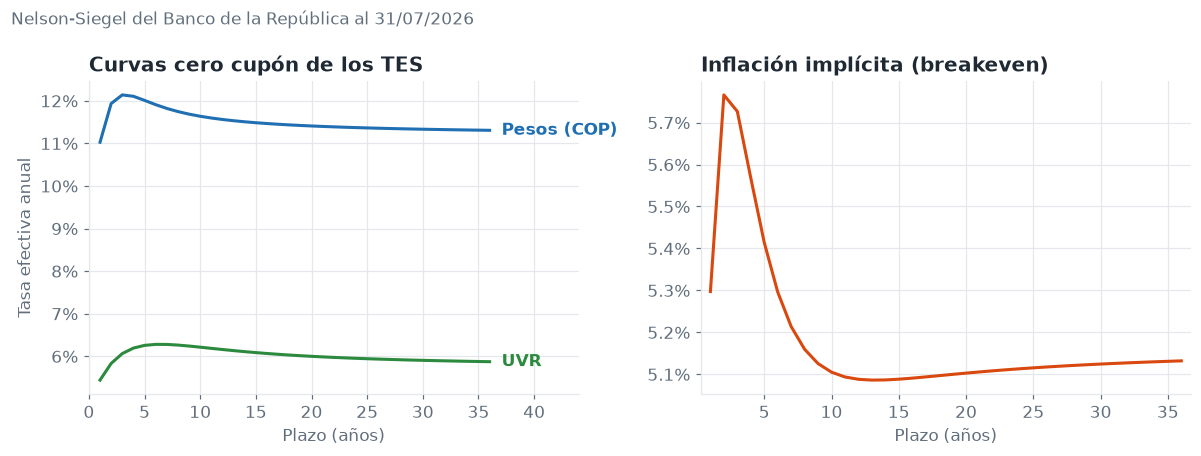

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
ax.plot(tenors, cop.iloc[-1], color=BLUE)
ax.plot(tenors, uvr.iloc[-1], color=GREEN)
ax.text(tenors[-1], cop.iloc[-1].iloc[-1], "  Pesos (COP)", color=BLUE, va="center", fontweight="bold")
ax.text(tenors[-1], uvr.iloc[-1].iloc[-1], "  UVR", color=GREEN, va="center", fontweight="bold")
ax.set_title("Curvas cero cupón de los TES")
ax.set_ylabel("Tasa efectiva anual")
ax = axes[1]
ax.plot(tenors, implied.iloc[-1], color=ORANGE)
ax.set_title("Inflación implícita (breakeven)")
for ax in axes:
    ax.set_xlabel("Plazo (años)")
    percent_axis(ax)
    ax.margins(x=0.02)
percent_axis(axes[1], decimals=1)
axes[0].set_xlim(0, tenors[-1] + 8)
fig.suptitle(f"Nelson-Siegel del Banco de la República al {origin_date:%d/%m/%Y}", x=0.01, ha="left", fontsize=11, color=MUTED)
fig.tight_layout()
plt.show()

## 2. Historia de la inflación implícita por plazo

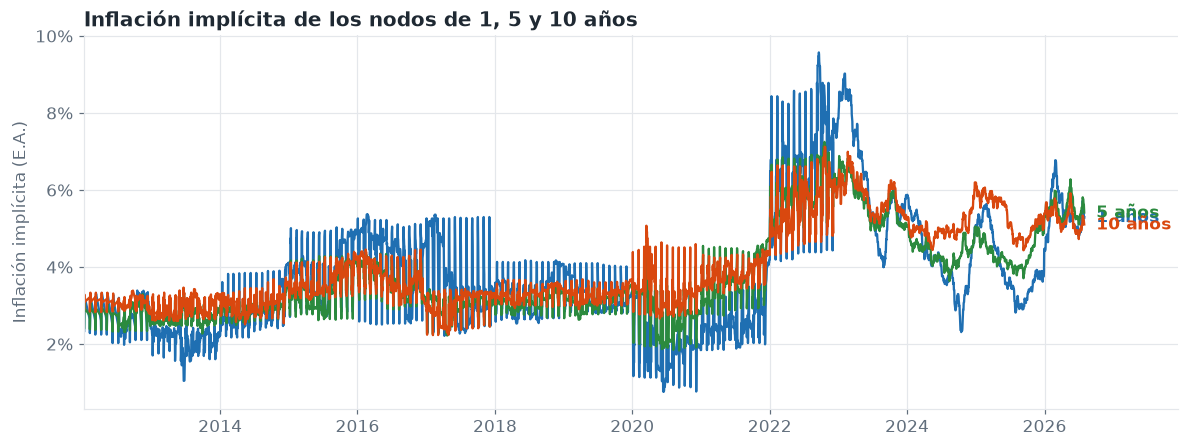

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for n, color in ((1, BLUE), (5, GREEN), (10, ORANGE)):
    ax.plot(implied.index, implied[n], color=color, linewidth=1.5)
    ax.text(implied.index[-1], implied[n].iloc[-1], f"  {n} años", color=color, va="center", fontweight="bold")
ax.set_title("Inflación implícita de los nodos de 1, 5 y 10 años")
ax.set_ylabel("Inflación implícita (E.A.)")
percent_axis(ax)
ax.set_xlim(implied.index[0], implied.index[-1] + pd.Timedelta(days=500))
fig.tight_layout()
plt.show()

## 3. Curvas simuladas por Hull-White (Monte Carlo)

Cada línea tenue es una curva posible de inflación implícita por plazo. Las bandas muestran el rango central (percentiles 25 a 75) y el rango amplio (5 a 95) de todas las trayectorias. La media coincide con la curva de hoy, porque el modelo está calibrado a ella.

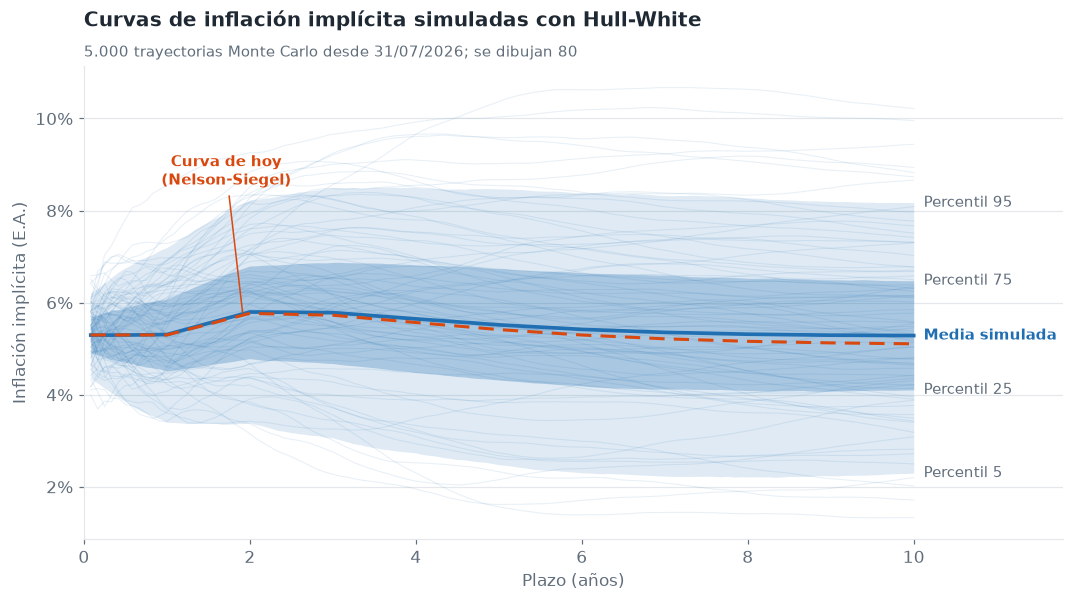

In [4]:
q05, q25, q50, q75, q95 = np.percentile(curves, [5, 25, 50, 75, 95], axis=0)
mean = curves.mean(axis=0)
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.plot(t, curves[rng.choice(N_PATHS, 80, replace=False)].T, color=BLUE, alpha=0.10, linewidth=0.7)
ax.fill_between(t, q05, q95, color=BLUE, alpha=0.14, linewidth=0)
ax.fill_between(t, q25, q75, color=BLUE, alpha=0.28, linewidth=0)
ax.plot(t, mean, color=BLUE, linewidth=2.4)
ax.plot(t, today, color=ORANGE, linewidth=2, linestyle=(0, (5, 3)))
x_end = t[-1]
pad = 0.12
ax.text(x_end + pad, q95[-1], "Percentil 95", color=MUTED, va="center", fontsize=10)
ax.text(x_end + pad, q75[-1], "Percentil 75", color=MUTED, va="center", fontsize=10)
ax.text(x_end + pad, mean[-1], "Media simulada", color=BLUE, va="center", fontweight="bold", fontsize=10)
ax.text(x_end + pad, q25[-1], "Percentil 25", color=MUTED, va="center", fontsize=10)
ax.text(x_end + pad, q05[-1], "Percentil 5", color=MUTED, va="center", fontsize=10)
ax.annotate("Curva de hoy\n(Nelson-Siegel)", xy=(t[22], today[22]), xytext=(t[22] - 0.2, today.max() + 0.028),
            color=ORANGE, fontweight="bold", fontsize=10, ha="center",
            arrowprops={"arrowstyle": "-", "color": ORANGE, "linewidth": 1})
ax.set_xlim(0, x_end + 1.8)
ax.set_xlabel("Plazo (años)")
ax.set_ylabel("Inflación implícita (E.A.)")
percent_axis(ax)
ax.grid(axis="x", visible=False)
ax.set_title("Curvas de inflación implícita simuladas con Hull-White", pad=26)
ax.text(0, 1.02, f"{N_PATHS:,} trayectorias Monte Carlo desde {origin_date:%d/%m/%Y}; se dibujan 80".replace(",", "."),
        transform=ax.transAxes, color=MUTED, fontsize=10)
fig.tight_layout()
plt.show()

## 4. Distribución simulada a distintos plazos

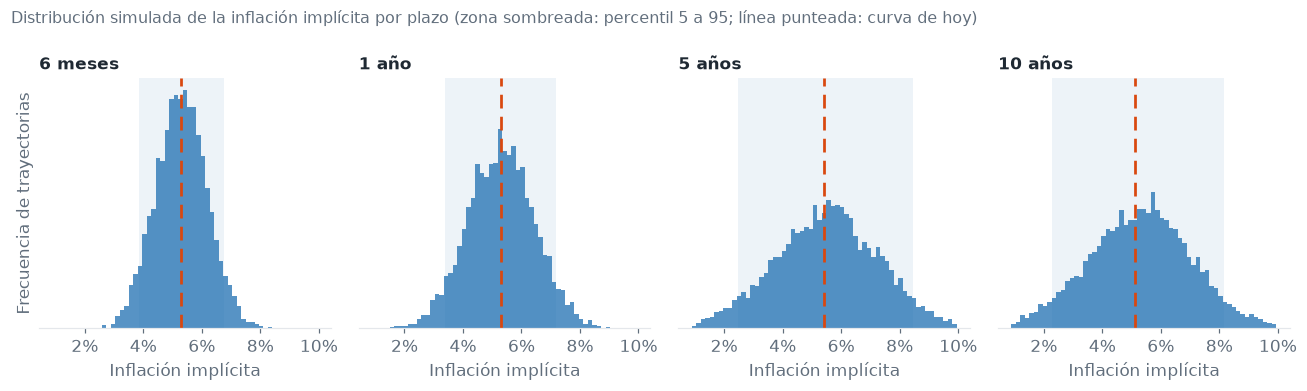

In [5]:
horizons = (0.5, 1, 5, 10)
lo = np.percentile(curves, 0.5)
hi = np.percentile(curves, 99.5)
bins = np.linspace(lo, hi, 60)
fig, axes = plt.subplots(1, len(horizons), figsize=(12, 3.6), sharex=True, sharey=True)
for ax, years in zip(axes, horizons, strict=True):
    col = int(np.argmin(np.abs(t - years)))
    values = curves[:, col]
    ax.hist(values, bins=bins, color=BLUE, alpha=0.75, linewidth=0)
    p5, p95 = np.percentile(values, [5, 95])
    ax.axvline(today[col], color=ORANGE, linestyle=(0, (5, 3)), linewidth=1.8)
    ax.axvspan(p5, p95, color=BLUE, alpha=0.08, linewidth=0)
    ax.set_title("6 meses" if t[col] < 1 else ("1 año" if round(t[col]) == 1 else f"{t[col]:g} años"), fontsize=11)
    ax.set_xlabel("Inflación implícita")
    percent_axis(ax, "x")
    ax.grid(False)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
axes[0].set_ylabel("Frecuencia de trayectorias")
fig.suptitle("Distribución simulada de la inflación implícita por plazo (zona sombreada: percentil 5 a 95; línea punteada: curva de hoy)",
             x=0.01, ha="left", fontsize=10.5, color=MUTED)
fig.tight_layout()
plt.show()

## 5. Pronóstico a 6 meses que usa `source: forecast`

El modelo toma la muestra de Hull-White a 6 meses y la corrige con el error pasado, la estacionalidad y la dispersión que falta. Los escenarios son p05 (bajo), mediana (base) y p99,5 (alto).

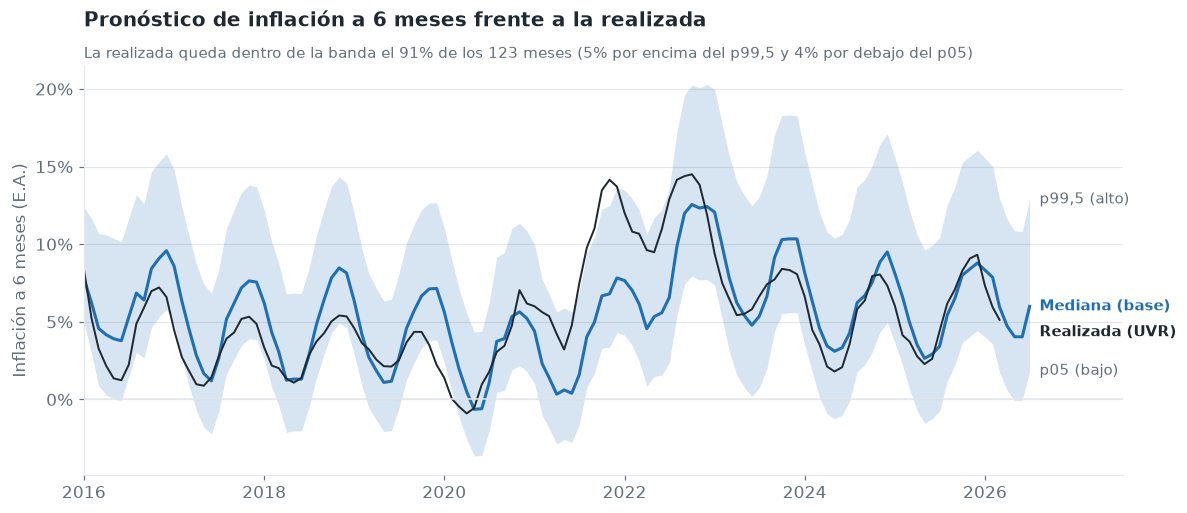

In [6]:
forecasts = pd.read_csv(ROOT / cfg["inflation_scenarios"]["forecast_file"], sep=";", index_col="month")
forecasts.index = pd.PeriodIndex(forecasts.index, freq="M")
uvr_series = load_uvr(cfg)
horizon = model["horizon_months"]
realised = {}
for month in forecasts.index:
    try:
        realised[month] = cpi_target(uvr_series, month.to_timestamp(how="end").normalize(), horizon)
    except ValueError:  # el objetivo aún no se realiza
        pass
realised = pd.Series(realised)
x = forecasts.index.to_timestamp()
f = forecasts.loc[realised.index]
inside = ((realised >= f["p05_ea"]) & (realised <= f["p995_ea"])).mean()
above = (realised > f["p995_ea"]).mean()
below = (realised < f["p05_ea"]).mean()

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.fill_between(x, forecasts["p05_ea"], forecasts["p995_ea"], color=BLUE, alpha=0.18, linewidth=0)
ax.plot(x, forecasts["median_ea"], color=BLUE, linewidth=2)
ax.plot(realised.index.to_timestamp(), realised, color=INK, linewidth=1.3)
ax.axhline(0, color=GRID, linewidth=1)
x_last = x[-1] + pd.Timedelta(days=40)
ax.text(x_last, forecasts["p995_ea"].iloc[-1], "p99,5 (alto)", color=MUTED, va="center", fontsize=10)
ax.text(x_last, forecasts["median_ea"].iloc[-1], "Mediana (base)", color=BLUE, va="center", fontweight="bold", fontsize=10)
ax.text(x_last, forecasts["p05_ea"].iloc[-1], "p05 (bajo)", color=MUTED, va="center", fontsize=10)
ax.text(x_last, realised.iloc[-1] - 0.008, "Realizada (UVR)", color=INK,
        va="center", fontweight="bold", fontsize=10)
ax.set_xlim(x[0], x[-1] + pd.Timedelta(days=380))
percent_axis(ax)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Inflación a 6 meses (E.A.)")
ax.set_title("Pronóstico de inflación a 6 meses frente a la realizada", pad=26)
ax.text(0, 1.02, f"La realizada queda dentro de la banda el {inside:.0%} de los {len(realised)} meses "
        f"({above:.0%} por encima del p99,5 y {below:.0%} por debajo del p05)".replace(".", ","),
        transform=ax.transAxes, color=MUTED, fontsize=10)
fig.tight_layout()
plt.show()